# Phân tích khách hàng rời mạng (Customer Churn) cho một công ty viễn thông

Bối cảnh (PwC case study): một công ty viễn thông đang mất nhiều khách mỗi tháng. CEO muốn biết:
1. Những khách hàng nào đang rời đi?
2. Yếu tố nào ảnh hưởng đến churn nhiều nhất?
3. Làm sao dự đoán trước và giữ chân họ?

Dữ liệu: `telco_churn.csv`, 3.333 khách hàng, 21 cột (thời gian dùng dịch vụ, số phút/cuộc gọi theo khung giờ, cước, số lần gọi tổng đài, gói quốc tế, gói voicemail, bang, mã vùng).

**Lưu ý về phạm vi:** brief của PwC có hỏi về tuổi, giới tính, loại hợp đồng, hình thức thanh toán, dịch vụ Internet/TV, nhưng bộ dữ liệu này **không có các cột đó**. Notebook này chỉ trả lời những gì dữ liệu cho phép, phần còn thiếu mình ghi lại ở cuối như đề xuất thu thập thêm.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
os.makedirs('figures', exist_ok=True)

BLUE = '#2F5D8A'
GREY = '#B8C2CC'

## 1. Đọc dữ liệu

Nếu chạy trên Google Colab: bấm Run all, đến ô dưới sẽ hiện nút **Choose Files**, chọn file `telco_churn.csv` trên máy.

In [2]:
path = 'data/telco_churn.csv'
if not os.path.exists(path):
    path = 'telco_churn.csv'
if not os.path.exists(path):   # chạy trên Colab thì tải file lên
    from google.colab import files
    uploaded = files.upload()
    path = list(uploaded.keys())[0]

df = pd.read_csv(path)
print(df.shape)
df.head()

(3333, 21)


,Account_Length,Vmail_Message,Day_Mins,Eve_Mins,Night_Mins,Intl_Mins,CustServ_Calls,Churn,Intl_Plan,Vmail_Plan,...,Day_Charge,Eve_Calls,Eve_Charge,Night_Calls,Night_Charge,Intl_Calls,Intl_Charge,State,Area_Code,Phone
0,128,25,265.1,197.4,244.7,10.0,1,no,no,yes,...,45.07,99,16.78,91,11.01,3,2.70,KS,415,382-4657
1,107,26,161.6,195.5,254.4,13.7,1,no,no,yes,...,27.47,103,16.62,103,11.45,3,3.70,OH,415,371-7191
2,137,0,243.4,121.2,162.6,12.2,0,no,no,no,...,41.38,110,10.30,104,7.32,5,3.29,NJ,415,358-1921
3,84,0,299.4,61.9,196.9,6.6,2,no,yes,no,...,50.90,88,5.26,89,8.86,7,1.78,OH,408,375-9999
4,75,0,166.7,148.3,186.9,10.1,3,no,yes,no,...,28.34,122,12.61,121,8.41,3,2.73,OK,415,330-6626


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Account_Length  3333 non-null   int64  
 1   Vmail_Message   3333 non-null   int64  
 2   Day_Mins        3333 non-null   float64
 3   Eve_Mins        3333 non-null   float64
 4   Night_Mins      3333 non-null   float64
 5   Intl_Mins       3333 non-null   float64
 6   CustServ_Calls  3333 non-null   int64  
 7   Churn           3333 non-null   str    
 8   Intl_Plan       3333 non-null   str    
 9   Vmail_Plan      3333 non-null   str    
 10  Day_Calls       3333 non-null   int64  
 11  Day_Charge      3333 non-null   float64
 12  Eve_Calls       3333 non-null   int64  
 13  Eve_Charge      3333 non-null   float64
 14  Night_Calls     3333 non-null   int64  
 15  Night_Charge    3333 non-null   float64
 16  Intl_Calls      3333 non-null   int64  
 17  Intl_Charge     3333 non-null   float64
 18 

In [4]:
print('Dòng trùng lặp:', df.duplicated().sum())
print('Số giá trị thiếu:', df.isna().sum().sum())
print('Số điện thoại khác nhau:', df['Phone'].nunique())

Dòng trùng lặp: 0
Số giá trị thiếu: 0
Số điện thoại khác nhau: 3333


Dữ liệu sạch: không thiếu, không trùng, mỗi dòng là 1 khách (Phone không lặp lại). Cột Churn đang là 'yes'/'no' nên mình đổi sang 1/0 để tính tỷ lệ.

In [5]:
df['Churn'] = (df['Churn'] == 'yes').astype(int)
df.describe().round(2)

,Account_Length,Vmail_Message,Day_Mins,Eve_Mins,Night_Mins,Intl_Mins,CustServ_Calls,Churn,Day_Calls,Day_Charge,Eve_Calls,Eve_Charge,Night_Calls,Night_Charge,Intl_Calls,Intl_Charge,Area_Code
count,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00,3333.00
mean,101.06,8.10,179.78,200.98,200.87,10.24,1.56,0.14,100.44,30.56,100.11,17.08,100.11,9.04,4.48,2.76,437.18
std,39.82,13.69,54.47,50.71,50.57,2.79,1.32,0.35,20.07,9.26,19.92,4.31,19.57,2.28,2.46,0.75,42.37
min,1.00,0.00,0.00,0.00,23.20,0.00,0.00,0.00,0.00,0.00,0.00,0.00,33.00,1.04,0.00,0.00,408.00
25%,74.00,0.00,143.70,166.60,167.00,8.50,1.00,0.00,87.00,24.43,87.00,14.16,87.00,7.52,3.00,2.30,408.00
50%,101.00,0.00,179.40,201.40,201.20,10.30,1.00,0.00,101.00,30.50,100.00,17.12,100.00,9.05,4.00,2.78,415.00
75%,127.00,20.00,216.40,235.30,235.30,12.10,2.00,0.00,114.00,36.79,114.00,20.00,113.00,10.59,6.00,3.27,510.00
max,243.00,51.00,350.80,363.70,395.00,20.00,9.00,1.00,165.00,59.64,170.00,30.91,175.00,17.77,20.00,5.40,510.00


## 2. Kiểm tra dữ liệu trước khi phân tích

### 2.1 Cột cước (Charge) có phải là thông tin mới không?

Mình thử chia cước cho số phút ở từng khung giờ:

In [6]:
for p in ['Day', 'Eve', 'Night', 'Intl']:
    rate = df[f'{p}_Charge'] / df[f'{p}_Mins']
    print(f'{p:6s} giá/phút: min {rate.min():.4f}  max {rate.max():.4f}  | tương quan phút-cước: {df[f"{p}_Mins"].corr(df[f"{p}_Charge"]):.4f}')

Day    giá/phút: min 0.1692  max 0.1705  | tương quan phút-cước: 1.0000
Eve    giá/phút: min 0.0849  max 0.0851  | tương quan phút-cước: 1.0000
Night  giá/phút: min 0.0448  max 0.0451  | tương quan phút-cước: 1.0000
Intl   giá/phút: min 0.2682  max 0.2727  | tương quan phút-cước: 1.0000


Cước = số phút × một mức giá cố định (ban ngày 0,17$/phút, buổi tối 0,085$, ban đêm 0,045$, quốc tế 0,27$). Tương quan bằng 1, nghĩa là Day_Charge và Day_Mins là **cùng một thông tin**. Nếu đưa cả hai vào mô hình thì feature importance sẽ bị chia đôi giữa hai cột, dễ đọc sai (trong bài trên lớp Day_Charge đứng top 1 nhưng thực chất là Day_Mins).

Cách xử lý: giữ số phút của từng khung giờ, bỏ 4 cột Charge, và tạo thêm 1 cột **Total_Charge** = tổng cước (tức hóa đơn của khách).

Một điều nữa: giá quốc tế của người có gói quốc tế và không có gói là như nhau:

In [7]:
df['Intl_Rate'] = df['Intl_Charge'] / df['Intl_Mins']
df.groupby('Intl_Plan')['Intl_Rate'].mean().round(4)

Intl_Plan
no     0.2701
yes    0.2700
Name: Intl_Rate, dtype: float64

Gói quốc tế **không giảm giá cước phút gọi**. Phần này sẽ quan trọng ở mục 4.

### 2.2 Area_Code có dùng được không?

In [8]:
pd.crosstab(df['State'], df['Area_Code']).head(8)

Area_Code,408,415,510
State,,,
AK,14,24,14
AL,25,40,15
AR,13,27,15
AZ,15,36,13
CA,7,17,10
CO,25,29,12
CT,22,39,13
DC,14,27,13


Chỉ có 3 mã vùng (408, 415, 510, đều là mã vùng của California) nhưng lại xuất hiện ở tất cả 51 bang. Cột này không khớp với State nên mình không dùng. Phone là mã định danh, cũng bỏ.

In [9]:
df['Total_Charge'] = df['Day_Charge'] + df['Eve_Charge'] + df['Night_Charge'] + df['Intl_Charge']
df['Total_Mins'] = df['Day_Mins'] + df['Eve_Mins'] + df['Night_Mins'] + df['Intl_Mins']
df[['Total_Mins', 'Total_Charge']].describe().round(1)

,Total_Mins,Total_Charge
count,3333.0,3333.0
mean,591.9,59.4
std,90.0,10.5
min,284.3,22.9
25%,531.5,52.4
50%,593.6,59.5
75%,652.4,66.5
max,885.0,96.2


## 3. Tổng quan churn

In [10]:
churn_rate = df['Churn'].mean()
lost_bill = df.loc[df['Churn'] == 1, 'Total_Charge'].sum()
total_bill = df['Total_Charge'].sum()

print(f'Tỷ lệ churn: {churn_rate:.1%} ({df["Churn"].sum()} / {len(df)} khách)')
print(f'Tổng cước của khách churn: ${lost_bill:,.0f} / ${total_bill:,.0f} ({lost_bill / total_bill:.1%})')
print(f'Cước trung bình: khách ở lại ${df.loc[df.Churn == 0, "Total_Charge"].mean():.1f}, khách rời đi ${df.loc[df.Churn == 1, "Total_Charge"].mean():.1f}')

Tỷ lệ churn: 14.5% (483 / 3333 khách)
Tổng cước của khách churn: $31,567 / $198,146 (15.9%)
Cước trung bình: khách ở lại $58.4, khách rời đi $65.4


14,5% khách rời đi nhưng họ chiếm 15,9% tổng cước, vì khách rời đi có hóa đơn cao hơn trung bình khoảng 7$. Tức là công ty đang mất những khách trả nhiều tiền hơn.

So sánh trung bình các chỉ số giữa 2 nhóm:

In [11]:
cols = ['Account_Length', 'Day_Mins', 'Eve_Mins', 'Night_Mins', 'Intl_Mins', 'Intl_Calls',
        'CustServ_Calls', 'Vmail_Message', 'Total_Charge']
compare = df.groupby('Churn')[cols].mean().T.round(2)
compare.columns = ['Ở lại', 'Rời đi']
compare['Chênh lệch %'] = ((compare['Rời đi'] / compare['Ở lại'] - 1) * 100).round(0)
compare

,Ở lại,Rời đi,Chênh lệch %
Account_Length,100.79,102.66,2.0
Day_Mins,175.18,206.91,18.0
Eve_Mins,199.04,212.41,7.0
Night_Mins,200.13,205.23,3.0
Intl_Mins,10.16,10.70,5.0
Intl_Calls,4.53,4.16,-8.0
CustServ_Calls,1.45,2.23,54.0
Vmail_Message,8.60,5.12,-40.0
Total_Charge,58.45,65.36,12.0


Khác biệt rõ nhất: số lần gọi tổng đài (+54%), số phút gọi ban ngày (+18%), tổng cước (+12%). Thời gian dùng dịch vụ (Account_Length) gần như bằng nhau.

## 4. Ai là người rời đi?

### 4.1 Số lần gọi tổng đài chăm sóc khách hàng

In [12]:
cs = df.groupby(df['CustServ_Calls'].clip(upper=6))['Churn'].agg(['mean', 'count'])
cs.index = [str(i) if i < 6 else '6+' for i in cs.index]
cs

,mean,count
0,0.131994,697
1,0.103302,1181
2,0.114625,759
3,0.102564,429
4,0.457831,166
5,0.606061,66
6+,0.628571,35


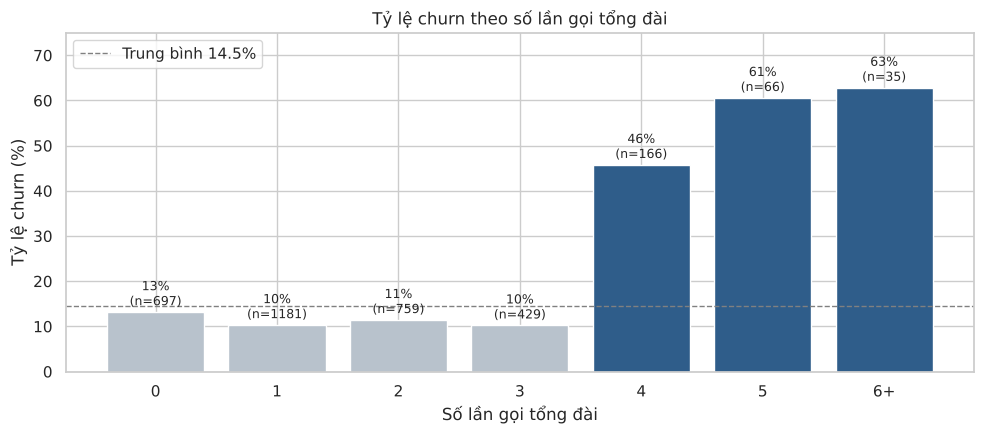

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [BLUE if i >= 4 else GREY for i in range(len(cs))]
ax.bar(cs.index, cs['mean'] * 100, color=colors)
ax.axhline(churn_rate * 100, color='grey', linestyle='--', linewidth=1, label=f'Trung bình {churn_rate:.1%}')
for i, (r, n) in enumerate(zip(cs['mean'], cs['count'])):
    ax.text(i, r * 100 + 1.5, f'{r:.0%}\n(n={n})', ha='center', fontsize=9)
ax.set_title('Tỷ lệ churn theo số lần gọi tổng đài')
ax.set_xlabel('Số lần gọi tổng đài')
ax.set_ylabel('Tỷ lệ churn (%)')
ax.set_ylim(0, 75)
ax.legend()
plt.tight_layout()
plt.savefig('figures/custserv_calls.png', dpi=150)
plt.show()

Từ 0 đến 3 cuộc gọi, tỷ lệ churn ổn định ở 10–13%. Đến **cuộc gọi thứ 4 thì nhảy lên 46%**, và từ 5 cuộc trở lên là trên 60%. Đây là ngưỡng rất rõ: khách gọi tổng đài lần thứ 4 nghĩa là vấn đề của họ chưa được giải quyết sau 3 lần.

Điều thú vị là nhóm gọi nhiều nhưng dùng ít mới là nhóm nguy hiểm nhất:

In [14]:
many_calls = df[df['CustServ_Calls'] >= 4]
many_calls.groupby(many_calls['Total_Charge'] > 60)['Churn'].agg(['mean', 'count'])

,mean,count
Total_Charge,,
False,0.774834,151
True,0.181034,116


Trong 267 khách gọi tổng đài từ 4 lần, nhóm có hóa đơn dưới 60$ churn tới 77%, còn nhóm hóa đơn cao chỉ 18%. Có thể hiểu là khách dùng nhiều có lý do để chịu đựng, còn khách dùng ít mà còn gặp sự cố thì rời đi ngay.

### 4.2 Gói cước: gói quốc tế và gói voicemail

In [15]:
plan = pd.DataFrame({
    'Gói quốc tế': df.groupby('Intl_Plan')['Churn'].mean(),
    'Gói voicemail': df.groupby('Vmail_Plan')['Churn'].mean()}).T * 100
plan.columns = ['Không có gói', 'Có gói']
print(df['Intl_Plan'].value_counts(), df['Vmail_Plan'].value_counts())
plan.round(1)

Intl_Plan
no     3010
yes     323
Name: count, dtype: int64 Vmail_Plan
no     2411
yes     922
Name: count, dtype: int64


,Không có gói,Có gói
Gói quốc tế,11.5,42.4
Gói voicemail,16.7,8.7


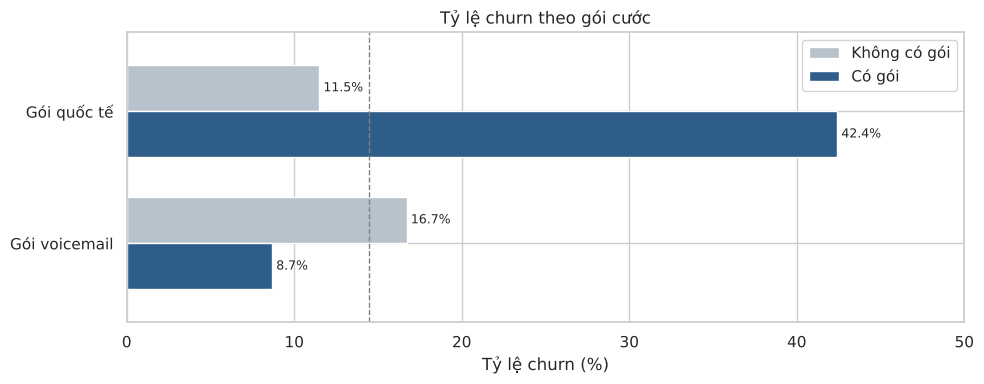

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
plan.plot(kind='barh', color=[GREY, BLUE], ax=ax, width=0.7)
ax.axvline(churn_rate * 100, color='grey', linestyle='--', linewidth=1)
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', padding=3, fontsize=9)
ax.set_title('Tỷ lệ churn theo gói cước')
ax.set_xlabel('Tỷ lệ churn (%)')
ax.set_xlim(0, 50)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('figures/plans.png', dpi=150)
plt.show()

- **Gói quốc tế**: 42,4% khách có gói này rời đi, gấp gần 4 lần người không có gói (11,5%).
- **Gói voicemail**: ngược lại, người có gói churn ít hơn một nửa (8,7% so với 16,7%).

Vì sao gói quốc tế lại làm khách rời đi? Ở mục 2.1 mình thấy gói này không giảm giá phút gọi. Xem kỹ hơn trong 323 khách có gói:

In [17]:
intl = df[df['Intl_Plan'] == 'yes'].copy()
intl['nhom_cuoc_goi'] = pd.cut(intl['Intl_Calls'], [-1, 2, 20], labels=['1-2 cuộc', '3+ cuộc'])
intl['nhom_phut'] = pd.cut(intl['Intl_Mins'], [-1, 13, 25], labels=['<= 13 phút', '> 13 phút'])
print(intl.groupby('nhom_cuoc_goi', observed=True)['Churn'].agg(['mean', 'count']))
print(intl.groupby('nhom_phut', observed=True)['Churn'].agg(['mean', 'count']))

                   mean  count
nhom_cuoc_goi                 
1-2 cuộc       1.000000     60
3+ cuộc        0.292776    263
                mean  count
nhom_phut                  
<= 13 phút  0.300752    266
> 13 phút   1.000000     57


In [18]:
intl['nhom'] = 'Gọi 3+ cuộc và <= 13 phút'
intl.loc[intl['Intl_Calls'] <= 2, 'nhom'] = 'Gọi ít (1-2 cuộc)'
intl.loc[intl['Intl_Mins'] > 13, 'nhom'] = 'Gọi nhiều phút (> 13)'
intl_grp = intl.groupby('nhom')['Churn'].agg(['mean', 'count']).sort_values('mean')
intl_grp

,mean,count
nhom,,
Gọi 3+ cuộc và <= 13 phút,0.122642,212
Gọi nhiều phút (> 13),1.000000,57
Gọi ít (1-2 cuộc),1.000000,54


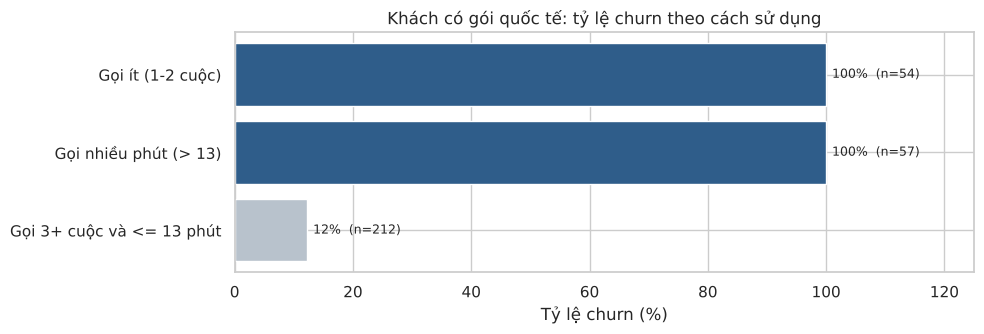

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(intl_grp.index, intl_grp['mean'] * 100, color=[GREY, BLUE, BLUE])
for i, (r, n) in enumerate(zip(intl_grp['mean'], intl_grp['count'])):
    ax.text(r * 100 + 1, i, f'{r:.0%}  (n={n})', va='center', fontsize=9)
ax.set_title('Khách có gói quốc tế: tỷ lệ churn theo cách sử dụng')
ax.set_xlabel('Tỷ lệ churn (%)')
ax.set_xlim(0, 125)
plt.tight_layout()
plt.savefig('figures/intl_plan.png', dpi=150)
plt.show()

Kết quả rất cực đoan: trong số khách có gói quốc tế, **tất cả 111 người** gọi quốc tế ít (1–2 cuộc) hoặc gọi nhiều phút (> 13 phút) đều đã rời đi. 212 người còn lại chỉ churn 12%, bằng mức chung.

Cách hiểu hợp lý: người gọi ít thấy trả tiền gói mà không dùng đến, còn người gọi nhiều thấy gói không giúp rẻ hơn (vẫn 0,27$/phút). Cả hai nhóm đều có lý do để chuyển sang nhà mạng khác có gói quốc tế tốt hơn. Dữ liệu không có phí thuê gói nên đây là suy luận, cần kiểm tra lại với bảng giá thực tế.

### 4.3 Hóa đơn và số phút gọi ban ngày

In [20]:
bill = df.groupby(pd.cut(df['Total_Charge'], [0, 40, 50, 60, 70, 80, 100]), observed=True)['Churn'].agg(['mean', 'count'])
bill.index = ['< 40$', '40-50$', '50-60$', '60-70$', '70-80$', '> 80$']
bill

,mean,count
< 40$,0.123894,113
40-50$,0.118852,488
50-60$,0.111210,1124
60-70$,0.056377,1082
70-80$,0.364045,445
> 80$,0.777778,81


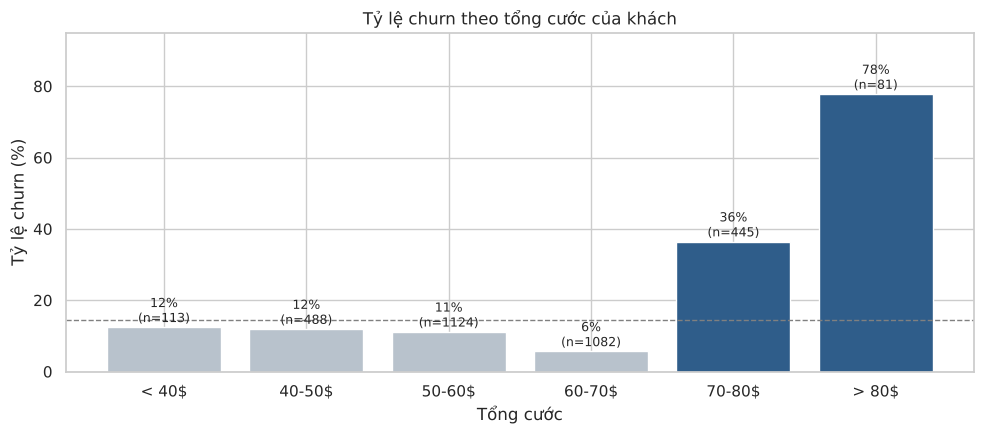

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [BLUE if i >= 4 else GREY for i in range(len(bill))]
ax.bar(bill.index, bill['mean'] * 100, color=colors)
ax.axhline(churn_rate * 100, color='grey', linestyle='--', linewidth=1)
for i, (r, n) in enumerate(zip(bill['mean'], bill['count'])):
    ax.text(i, r * 100 + 1.5, f'{r:.0%}\n(n={n})', ha='center', fontsize=9)
ax.set_title('Tỷ lệ churn theo tổng cước của khách')
ax.set_xlabel('Tổng cước')
ax.set_ylabel('Tỷ lệ churn (%)')
ax.set_ylim(0, 95)
plt.tight_layout()
plt.savefig('figures/bill.png', dpi=150)
plt.show()

Khách có hóa đơn dưới 70$ churn 6–12%. Trên 70$ thì tăng vọt lên 36%, trên 80$ là 78%. Đây là những khách dùng nhiều nhất và trả nhiều nhất. Nguyên nhân chủ yếu đến từ phút gọi ban ngày (giá đắt nhất, 0,17$/phút):

In [22]:
df.groupby(pd.cut(df['Day_Mins'], [-1, 150, 200, 225, 250, 275, 400]), observed=True)['Churn'].agg(['mean', 'count']).round(3)

,mean,count
Day_Mins,,
"(-1, 150]",0.118,979
"(150, 200]",0.090,1168
"(200, 225]",0.068,527
"(225, 250]",0.218,331
"(250, 275]",0.357,196
"(275, 400]",0.636,132


Gọi ban ngày trên 250 phút thì tỷ lệ churn từ 36% trở lên. Công ty đang tính giá theo phút cố định, không có ưu đãi cho người dùng nhiều, nên khách lớn dễ bị đối thủ lôi kéo bằng gói không giới hạn.

Một chi tiết: khách có gói voicemail và hóa đơn cao lại churn rất thấp:

In [23]:
df.groupby(['Vmail_Plan', df['Total_Charge'] > 70])['Churn'].agg(['mean', 'count']).round(3)

mean  count
Vmail_Plan Total_Charge              
no         False         0.093   2043
           True          0.582    368
yes        False         0.090    764
           True          0.070    158

Hóa đơn trên 70$ mà không có voicemail: churn 58%. Có voicemail: chỉ 7%. Mình chưa giải thích được nguyên nhân từ dữ liệu này (có thể gói voicemail đi kèm một gói cước khác), nhưng đây là điểm đáng hỏi thêm khách hàng.

### 4.4 Thời gian dùng dịch vụ và địa lý

In [24]:
tenure = df.groupby(pd.qcut(df['Account_Length'], 5), observed=True)['Churn'].agg(['mean', 'count'])
tenure

,mean,count
Account_Length,,
"(0.999, 67.0]",0.130178,676
"(67.0, 91.0]",0.135965,684
"(91.0, 111.0]",0.160796,653
"(111.0, 134.0]",0.157100,662
"(134.0, 243.0]",0.141337,658


Tỷ lệ churn gần như như nhau (13–16%) dù khách mới hay khách lâu năm. Vậy churn ở đây không phải chuyện "khách mới chưa gắn bó" mà là do trải nghiệm và giá cước.

In [25]:
state = df.groupby('State')['Churn'].agg(['mean', 'count']).sort_values('mean', ascending=False)
print('Số khách mỗi bang: từ', state['count'].min(), 'đến', state['count'].max())
state.head(6)

Số khách mỗi bang: từ 34 đến 106


,mean,count
State,,
CA,0.264706,34
NJ,0.264706,68
TX,0.250000,72
MD,0.242857,70
SC,0.233333,60
MI,0.219178,73


In [26]:
from scipy.stats import chi2_contingency
p_state = chi2_contingency(pd.crosstab(df['State'], df['Churn']))[1]
p_area = chi2_contingency(pd.crosstab(df['Area_Code'], df['Churn']))[1]
print(f'Kiểm định chi-square State: p = {p_state:.4f}')
print(f'Kiểm định chi-square Area_Code: p = {p_area:.4f}')

Kiểm định chi-square State: p = 0.0023
Kiểm định chi-square Area_Code: p = 0.9151


Khác biệt giữa các bang có ý nghĩa thống kê (p = 0,002), CA và NJ cao nhất (26%). Nhưng mỗi bang chỉ có khoảng 65 khách (CA chỉ 34 khách, tức 9 người rời đi), nên con số theo từng bang dao động mạnh. Mình chỉ ghi nhận đây là điểm cần theo dõi thêm, không dùng để ra quyết định.

### 4.5 Tương quan giữa các biến

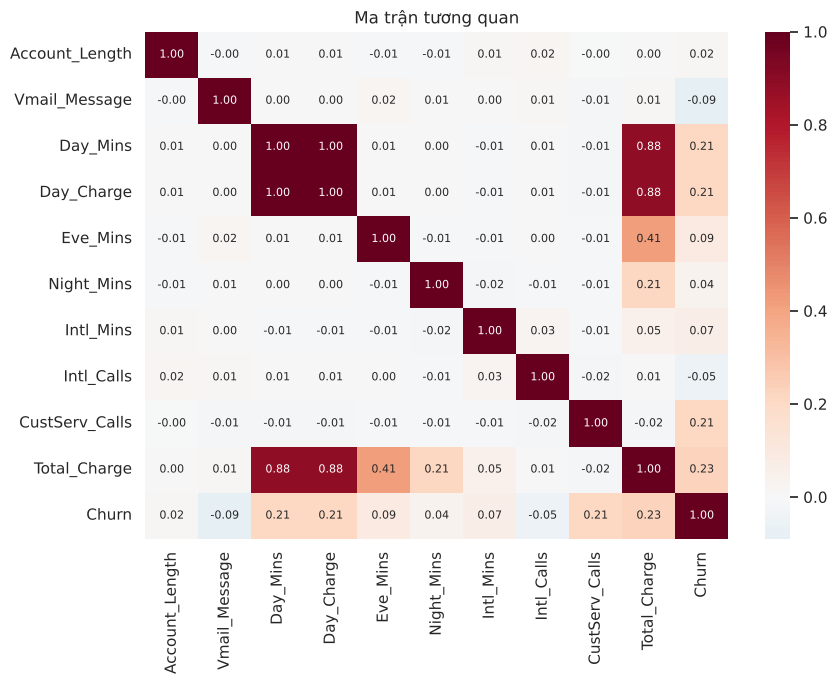

In [27]:
num = df[['Account_Length', 'Vmail_Message', 'Day_Mins', 'Day_Charge', 'Eve_Mins', 'Night_Mins',
          'Intl_Mins', 'Intl_Calls', 'CustServ_Calls', 'Total_Charge', 'Churn']]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax, annot_kws={'size': 8})
ax.set_title('Ma trận tương quan')
plt.tight_layout()
plt.savefig('figures/correlation.png', dpi=150)
plt.show()

Tương quan tuyến tính với Churn đều thấp (cao nhất là Total_Charge 0,23, sau đó là CustServ_Calls và Day_Mins 0,21), trong khi các biểu đồ ở trên cho thấy quan hệ rất mạnh. Lý do là quan hệ ở đây có **ngưỡng** (4 cuộc gọi, 70$) chứ không tăng đều, nên hệ số tương quan không bắt được. Đây cũng là lý do mình dự đoán mô hình cây quyết định sẽ tốt hơn Logistic Regression.

## 5. Mô hình dự đoán churn

### 5.1 Chuẩn bị dữ liệu

- Đổi Intl_Plan, Vmail_Plan sang 0/1
- Bỏ: Phone (mã định danh), Area_Code (không khớp với bang), State (51 giá trị, mỗi bang quá ít khách), 4 cột Charge (trùng thông tin với số phút)
- Chia train/test 75/25, dùng `stratify` để tỷ lệ churn ở 2 tập giống nhau
- Chuẩn hóa (StandardScaler) chỉ cho Logistic Regression, và **fit trên tập train** rồi mới áp dụng cho tập test, để mô hình không "nhìn thấy" dữ liệu test

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

data = df.copy()
data['Intl_Plan'] = (data['Intl_Plan'] == 'yes').astype(int)
data['Vmail_Plan'] = (data['Vmail_Plan'] == 'yes').astype(int)

features = ['Account_Length', 'Intl_Plan', 'Vmail_Plan', 'Vmail_Message',
            'Day_Mins', 'Day_Calls', 'Eve_Mins', 'Eve_Calls', 'Night_Mins', 'Night_Calls',
            'Intl_Mins', 'Intl_Calls', 'CustServ_Calls', 'Total_Charge']
X = data[features]
y = data['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print('Train:', X_train.shape, f'churn {y_train.mean():.1%}')
print('Test: ', X_test.shape, f'churn {y_test.mean():.1%}')

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

Train: (2499, 14) churn 14.5%
Test:  (834, 14) churn 14.5%


Mốc so sánh: nếu đoán tất cả khách đều ở lại thì accuracy đã là 85,5%. Vì vậy accuracy không nói lên nhiều, mình sẽ nhìn **recall** (bắt được bao nhiêu % khách sẽ rời đi), **precision** (trong số khách bị cảnh báo, bao nhiêu % thật sự rời đi) và **AUC**.

In [29]:
print(f'Accuracy nếu đoán tất cả là "ở lại": {1 - y_test.mean():.1%}')

Accuracy nếu đoán tất cả là "ở lại": 85.5%


### 5.2 Huấn luyện 3 mô hình

In [30]:
def evaluate(name, y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {'Mô hình': name,
            'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred),
            'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'AUC': roc_auc_score(y_true, prob)}

# Logistic Regression
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_sc, y_train)
prob_lr = logreg.predict_proba(X_test_sc)[:, 1]

# Decision Tree: giới hạn độ sâu = 5 để cây không học thuộc dữ liệu train
tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_train, y_train)
prob_tree = tree.predict_proba(X_test)[:, 1]

# XGBoost
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
xgb.fit(X_train, y_train)
prob_xgb = xgb.predict_proba(X_test)[:, 1]

results = pd.DataFrame([evaluate('Logistic Regression', y_test, prob_lr),
                        evaluate('Decision Tree (depth 5)', y_test, prob_tree),
                        evaluate('XGBoost', y_test, prob_xgb)]).set_index('Mô hình')
results.round(3)

,Accuracy,Precision,Recall,F1,AUC
Mô hình,,,,,
Logistic Regression,0.861,0.545,0.248,0.341,0.811
Decision Tree (depth 5),0.969,0.990,0.793,0.881,0.884
XGBoost,0.971,1.000,0.802,0.890,0.918


Mình cũng thử cây không giới hạn độ sâu (như bài trên lớp) để so sánh:

In [31]:
tree_full = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print('Độ sâu cây:', tree_full.get_depth())
print('Accuracy trên train:', accuracy_score(y_train, tree_full.predict(X_train)))
pd.DataFrame([evaluate('Decision Tree (không giới hạn)', y_test, tree_full.predict_proba(X_test)[:, 1])]).set_index('Mô hình').round(3)

Độ sâu cây: 21
Accuracy trên train: 1.0


,Accuracy,Precision,Recall,F1,AUC
Mô hình,,,,,
Decision Tree (không giới hạn),0.938,0.776,0.802,0.789,0.881


Cây không giới hạn đạt 100% trên train nhưng F1 trên test thấp hơn (0,79 so với 0,88): cây học thuộc dữ liệu train (overfitting). Giới hạn độ sâu = 5 cho kết quả tốt hơn và cây cũng dễ đọc hơn.

Nhận xét kết quả:
- **Logistic Regression** yếu nhất: chỉ bắt được 25% khách rời đi. Đúng như dự đoán ở mục 4.5, quan hệ có ngưỡng nên mô hình tuyến tính không phù hợp.
- **Decision Tree** và **XGBoost** tốt hơn hẳn: bắt được khoảng 80% khách rời đi, và gần như mọi cảnh báo đều đúng (precision 99–100%).
- XGBoost có AUC cao nhất (0,92), tức là xếp hạng rủi ro tốt nhất.

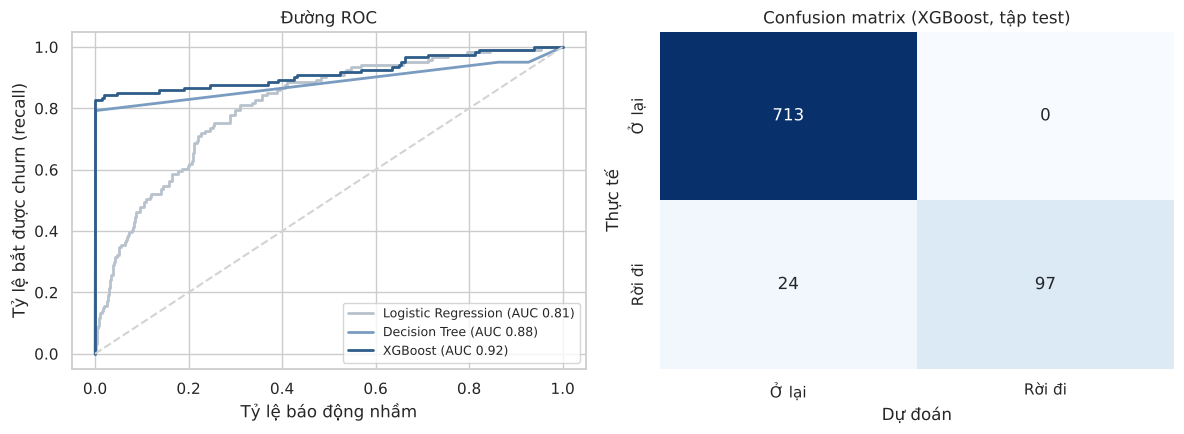

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name, prob, color in [('Logistic Regression', prob_lr, GREY),
                          ('Decision Tree', prob_tree, '#7A9CC0'),
                          ('XGBoost', prob_xgb, BLUE)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=color, linewidth=2, label=f'{name} (AUC {roc_auc_score(y_test, prob):.2f})')
axes[0].plot([0, 1], [0, 1], color='lightgrey', linestyle='--')
axes[0].set_title('Đường ROC')
axes[0].set_xlabel('Tỷ lệ báo động nhầm')
axes[0].set_ylabel('Tỷ lệ bắt được churn (recall)')
axes[0].legend(loc='lower right', fontsize=9)

cm = confusion_matrix(y_test, (prob_xgb >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Ở lại', 'Rời đi'], yticklabels=['Ở lại', 'Rời đi'])
axes[1].set_title('Confusion matrix (XGBoost, tập test)')
axes[1].set_xlabel('Dự đoán')
axes[1].set_ylabel('Thực tế')

plt.tight_layout()
plt.savefig('figures/model_results.png', dpi=150)
plt.show()

Trên 834 khách trong tập test: mô hình cảnh báo 97 khách và cả 97 đều thật sự rời đi. Còn bỏ sót 24 khách (20%).

### 5.3 Dùng mô hình để ưu tiên chăm sóc

Trong thực tế, đội chăm sóc khách hàng không gọi được cho tất cả mọi người. Câu hỏi là: nếu chỉ liên hệ X% khách có điểm rủi ro cao nhất thì bắt được bao nhiêu % khách sẽ rời đi?

In [33]:
test = X_test.copy()
test['Churn'] = y_test
test['risk'] = prob_xgb
test = test.sort_values('risk', ascending=False)

for pct in [0.05, 0.10, 0.15, 0.20, 0.30]:
    top = test.head(int(len(test) * pct))
    print(f'Liên hệ top {pct:.0%} rủi ro cao ({len(top)} khách): bắt được {top["Churn"].sum() / test["Churn"].sum():.0%} khách rời đi')

Liên hệ top 5% rủi ro cao (41 khách): bắt được 34% khách rời đi
Liên hệ top 10% rủi ro cao (83 khách): bắt được 69% khách rời đi
Liên hệ top 15% rủi ro cao (125 khách): bắt được 84% khách rời đi
Liên hệ top 20% rủi ro cao (166 khách): bắt được 85% khách rời đi
Liên hệ top 30% rủi ro cao (250 khách): bắt được 87% khách rời đi


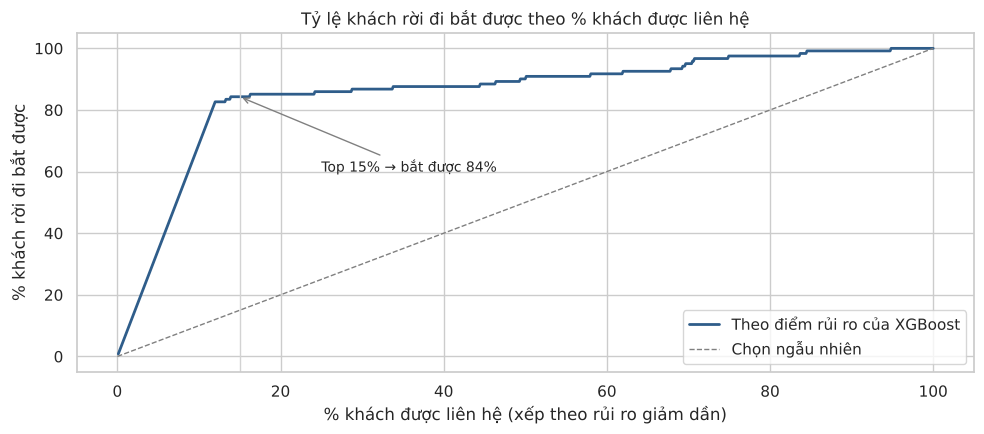

In [34]:
pcts = np.arange(1, len(test) + 1) / len(test) * 100
captured = test['Churn'].cumsum() / test['Churn'].sum() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(pcts, captured, color=BLUE, linewidth=2, label='Theo điểm rủi ro của XGBoost')
ax.plot([0, 100], [0, 100], color='grey', linestyle='--', linewidth=1, label='Chọn ngẫu nhiên')
ax.axvline(15, color='lightgrey', linewidth=1)
ax.annotate(f'Top 15% → bắt được {captured.iloc[int(len(test) * 0.15) - 1]:.0f}%',
            xy=(15, captured.iloc[int(len(test) * 0.15) - 1]), xytext=(25, 60),
            arrowprops=dict(arrowstyle='->', color='grey'), fontsize=10)
ax.set_title('Tỷ lệ khách rời đi bắt được theo % khách được liên hệ')
ax.set_xlabel('% khách được liên hệ (xếp theo rủi ro giảm dần)')
ax.set_ylabel('% khách rời đi bắt được')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/gain_chart.png', dpi=150)
plt.show()

Chỉ cần liên hệ 15% khách có rủi ro cao nhất là đã bắt được 84% khách sắp rời đi. Nếu chọn ngẫu nhiên thì 15% khách chỉ bắt được khoảng 15%. Sau mốc 15% thì đường gần như đi ngang, liên hệ thêm không bắt thêm được bao nhiêu.

## 6. Yếu tố nào quan trọng nhất?

In [35]:
importance = pd.DataFrame({
    'Decision Tree': tree.feature_importances_,
    'XGBoost': xgb.feature_importances_}, index=features).sort_values('XGBoost', ascending=False)
importance.round(3)

,Decision Tree,XGBoost
Total_Charge,0.476,0.239
CustServ_Calls,0.138,0.202
Vmail_Plan,0.130,0.152
Intl_Plan,0.080,0.150
Intl_Calls,0.072,0.070
Intl_Mins,0.097,0.050
Night_Mins,0.003,0.019
Eve_Calls,0.000,0.018
Account_Length,0.001,0.018
Day_Mins,0.000,0.018


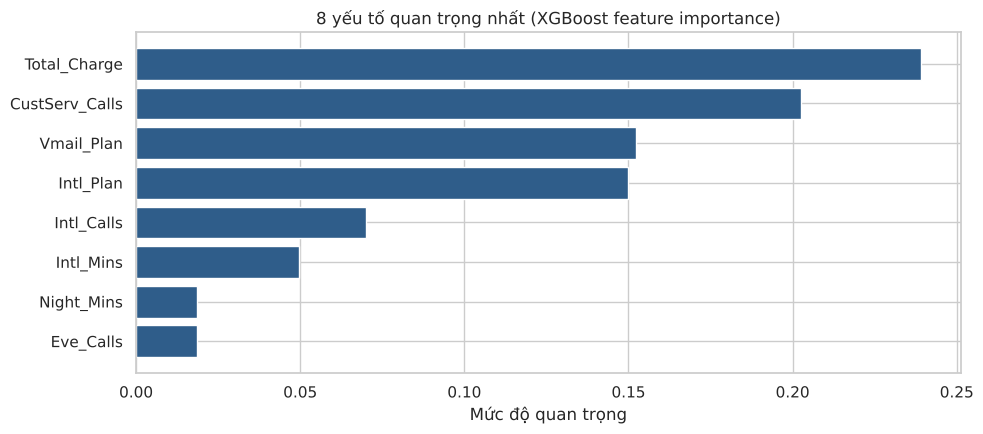

In [36]:
top_imp = importance.head(8).sort_values('XGBoost')
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(top_imp.index, top_imp['XGBoost'], color=BLUE)
ax.set_title('8 yếu tố quan trọng nhất (XGBoost feature importance)')
ax.set_xlabel('Mức độ quan trọng')
plt.tight_layout()
plt.savefig('figures/importance.png', dpi=150)
plt.show()

Cả hai mô hình đều đồng ý về nhóm yếu tố hàng đầu:
1. **Total_Charge** (tổng cước): khách trả nhiều thì dễ rời đi
2. **CustServ_Calls** (số lần gọi tổng đài)
3. **Vmail_Plan** và **Intl_Plan** (gói cước)
4. **Intl_Calls**, **Intl_Mins** (cách dùng gói quốc tế)

Account_Length, số cuộc gọi trong ngày, phút gọi buổi tối và ban đêm gần như không quan trọng. Kết quả này khớp với phần EDA.

Cây quyết định cho phép đọc ra luật cụ thể. Mình vẽ 3 tầng đầu để dễ đọc:

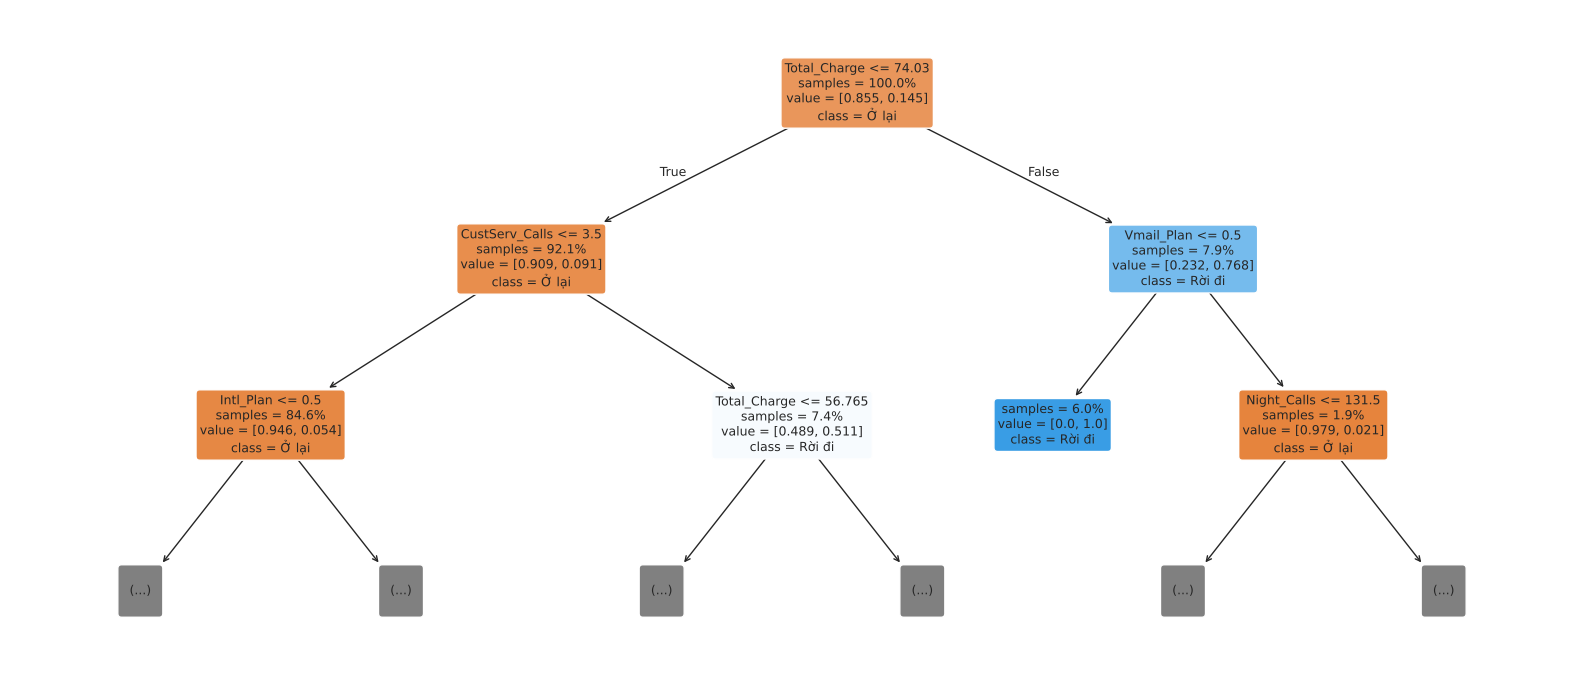

In [37]:
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree, max_depth=2, feature_names=features, class_names=['Ở lại', 'Rời đi'],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=9, ax=ax)
plt.tight_layout()
plt.savefig('figures/tree.png', dpi=150)
plt.show()

In [38]:
print(export_text(tree, feature_names=features, max_depth=3))

|--- Total_Charge <= 74.03
|   |--- CustServ_Calls <= 3.50
|   |   |--- Intl_Plan <= 0.50
|   |   |   |--- Vmail_Message <= 47.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Vmail_Message >  47.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- Intl_Plan >  0.50
|   |   |   |--- Intl_Calls <= 2.50
|   |   |   |   |--- class: 1
|   |   |   |--- Intl_Calls >  2.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- CustServ_Calls >  3.50
|   |   |--- Total_Charge <= 56.77
|   |   |   |--- class: 1
|   |   |--- Total_Charge >  56.77
|   |   |   |--- CustServ_Calls <= 8.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- CustServ_Calls >  8.00
|   |   |   |   |--- class: 1
|--- Total_Charge >  74.03
|   |--- Vmail_Plan <= 0.50
|   |   |--- class: 1
|   |--- Vmail_Plan >  0.50
|   |   |--- Night_Calls <= 131.50
|   |   |   |--- class: 0
|   |   |--- Night_Calls >  131.50
|   |   |   |--- Intl_Calls <= 5.50
|   |   |   |   |--- class

### 6.1 Ba nhóm rủi ro dễ nhận biết

Từ EDA và cây quyết định, mình gom lại thành 3 điều kiện đơn giản mà đội kinh doanh có thể dùng ngay, không cần chạy mô hình:
- Gọi tổng đài từ 4 lần trở lên
- Tổng cước trên 70$
- Có gói quốc tế

In [39]:
df['call_4plus'] = df['CustServ_Calls'] >= 4
df['bill_70plus'] = df['Total_Charge'] > 70
df['intl_plan'] = df['Intl_Plan'] == 'yes'
df['any_risk'] = df['call_4plus'] | df['bill_70plus'] | df['intl_plan']

rows = []
for col, name in [('call_4plus', 'Gọi tổng đài >= 4 lần'), ('bill_70plus', 'Tổng cước > 70$'),
                  ('intl_plan', 'Có gói quốc tế'), ('any_risk', 'Có ít nhất 1 dấu hiệu')]:
    g = df[df[col]]
    rows.append({'Nhóm': name, 'Số khách': len(g), '% khách': len(g) / len(df),
                 'Tỷ lệ churn': g['Churn'].mean(), '% tổng số khách churn': g['Churn'].sum() / df['Churn'].sum()})
g = df[~df['any_risk']]
rows.append({'Nhóm': 'Không có dấu hiệu nào', 'Số khách': len(g), '% khách': len(g) / len(df),
             'Tỷ lệ churn': g['Churn'].mean(), '% tổng số khách churn': g['Churn'].sum() / df['Churn'].sum()})
segments = pd.DataFrame(rows).set_index('Nhóm')
segments.style.format({'% khách': '{:.0%}', 'Tỷ lệ churn': '{:.1%}', '% tổng số khách churn': '{:.0%}'})

,Số khách,% khách,Tỷ lệ churn,% tổng số khách churn
Nhóm,,,,
Gọi tổng đài >= 4 lần,267,8%,51.7%,29%
Tổng cước > 70$,526,16%,42.8%,47%
Có gói quốc tế,323,10%,42.4%,28%
Có ít nhất 1 dấu hiệu,980,29%,43.3%,88%
Không có dấu hiệu nào,2353,71%,2.5%,12%


29% khách có ít nhất 1 trong 3 dấu hiệu, nhưng nhóm này chiếm **88% số khách rời đi** (churn 43%). 71% khách còn lại chỉ churn 2,5%.

## 7. Kết luận và đề xuất

**1. Ai đang rời đi?** 14,5% khách (483 người), chiếm 15,9% tổng cước. Họ thuộc 3 nhóm chính: khách gọi tổng đài nhiều lần, khách dùng nhiều (hóa đơn > 70$) và khách có gói quốc tế. Thời gian dùng dịch vụ không ảnh hưởng.

**2. Yếu tố nào quan trọng nhất?** Tổng cước, số lần gọi tổng đài, gói voicemail và gói quốc tế.

**3. Dự đoán và phòng ngừa thế nào?** Mô hình XGBoost bắt được 80% khách sẽ rời đi với precision gần 100%. Liên hệ 15% khách rủi ro cao nhất là bắt được 84% số khách sắp rời đi.

| Đề xuất | Dựa trên |
|---|---|
| Chuyển thẳng lên bộ phận xử lý cấp cao khi khách gọi tổng đài lần thứ 3 | Churn nhảy từ 10% lên 46% ở cuộc gọi thứ 4 |
| Thiết kế lại gói quốc tế: giảm giá phút gọi, hoặc chủ động chuyển khách gọi ít về gói không có quốc tế | Gói không giảm giá phút; 111 khách dùng gói không hợp đều rời đi |
| Gói không giới hạn / giảm giá theo bậc cho khách dùng nhiều phút ban ngày | Hóa đơn > 70$ churn 36–78% |
| Chạy mô hình hằng tháng, gọi điện giữ chân top 15% khách rủi ro cao | Bắt được 84% khách sắp rời đi trong tập test |
| Tìm hiểu vì sao khách có voicemail churn thấp, thử tặng voicemail cho khách hóa đơn cao | Hóa đơn > 70$: 7% churn nếu có voicemail, 58% nếu không |

**Hạn chế:**
- Không có dữ liệu nhân khẩu học, loại hợp đồng, hình thức thanh toán, dịch vụ Internet/TV như brief yêu cầu, nên chưa trả lời được các câu hỏi đó. Đề xuất bổ sung các cột này cho lần phân tích sau.
- Không có phí thuê gói và thời điểm rời đi, nên chưa tính được chi phí giữ chân so với doanh thu giữ lại được.
- Dữ liệu là ảnh chụp tại 1 thời điểm (3.333 khách), không theo dõi được theo thời gian. Mô hình cần được kiểm tra lại trên dữ liệu mới trước khi dùng thật.